In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [6]:
file_path = "../data/cleaned_transactions.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 511566
Columns: 9


C:\Users\USER\AppData\Local\Temp\ipykernel_35400\2758030996.py:3: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [7]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 511566 entries, 0 to 511565
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      511566 non-null  object 
 1   StockCode    511566 non-null  str    
 2   Description  511566 non-null  str    
 3   Quantity     511566 non-null  int64  
 4   InvoiceDate  511566 non-null  str    
 5   Price        511566 non-null  float64
 6   Customer ID  407664 non-null  float64
 7   Country      511566 non-null  str    
 8   Sales        511566 non-null  float64
dtypes: float64(3), int64(1), object(1), str(4)
memory usage: 35.1+ MB


In [9]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print(df["InvoiceDate"].dtype)

datetime64[us]


In [10]:
daily_sales = (
    df
    .set_index("InvoiceDate")
    .resample("D")["Sales"]
    .sum()
)

daily_sales.head()

InvoiceDate
2009-12-01    54513.50
2009-12-02    63352.51
2009-12-03    74037.91
2009-12-04    40732.92
2009-12-05     9803.05
Freq: D, Name: Sales, dtype: float64

In [11]:
print("Start:", daily_sales.index.min())
print("End:", daily_sales.index.max())
print("Number of days:", len(daily_sales))

Start: 2009-12-01 00:00:00
End: 2010-12-09 00:00:00
Number of days: 374


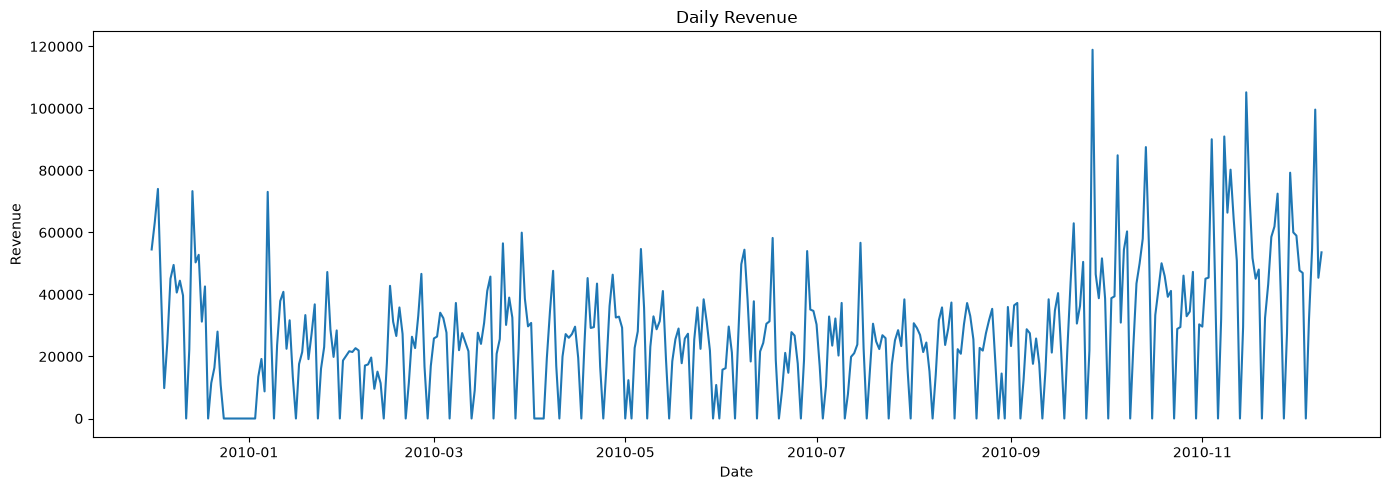

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [13]:
forecast_df = daily_sales.reset_index()

forecast_df.columns = ["Date", "Revenue"]

forecast_df.head()

,Date,Revenue
0,2009-12-01,54513.50
1,2009-12-02,63352.51
2,2009-12-03,74037.91
3,2009-12-04,40732.92
4,2009-12-05,9803.05


In [14]:
forecast_df["Day"] = forecast_df["Date"].dt.day
forecast_df["Month"] = forecast_df["Date"].dt.month
forecast_df["Year"] = forecast_df["Date"].dt.year
forecast_df["DayOfWeek"] = forecast_df["Date"].dt.dayofweek

forecast_df.head()

,Date,Revenue,Day,Month,Year,DayOfWeek
0,2009-12-01,54513.50,1,12,2009,1
1,2009-12-02,63352.51,2,12,2009,2
2,2009-12-03,74037.91,3,12,2009,3
3,2009-12-04,40732.92,4,12,2009,4
4,2009-12-05,9803.05,5,12,2009,5


In [15]:
print("Rows:", len(forecast_df))
print("Columns:", forecast_df.columns.tolist())

forecast_df.info()

Rows: 374
Columns: ['Date', 'Revenue', 'Day', 'Month', 'Year', 'DayOfWeek']
<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       374 non-null    datetime64[us]
 1   Revenue    374 non-null    float64       
 2   Day        374 non-null    int32         
 3   Month      374 non-null    int32         
 4   Year       374 non-null    int32         
 5   DayOfWeek  374 non-null    int32         
dtypes: datetime64[us](1), float64(1), int32(4)
memory usage: 11.8 KB


In [16]:
split_index = int(len(forecast_df) * 0.8)

train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining period:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nTesting period:")
print(test["Date"].min(), "to", test["Date"].max())

Training rows: 299
Testing rows: 75

Training period:
2009-12-01 00:00:00 to 2010-09-25 00:00:00

Testing period:
2010-09-26 00:00:00 to 2010-12-09 00:00:00


In [17]:
features = ["Day", "Month", "Year", "DayOfWeek"]

X_train = train[features]
y_train = train["Revenue"]

X_test = test[features]
y_test = test["Revenue"]

In [18]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [19]:
predictions = model.predict(X_test)

test["PredictedRevenue"] = predictions

test[["Date", "Revenue", "PredictedRevenue"]].head(10)

,Date,Revenue,PredictedRevenue
299,2010-09-26,21905.72,12722.564374
300,2010-09-27,118909.67,34003.751158
301,2010-09-28,46550.84,30402.013186
302,2010-09-29,38789.98,26800.275213
303,2010-09-30,51641.94,23198.537241
304,2010-10-01,38701.58,21248.640516
305,2010-10-02,0.00,17646.902544
306,2010-10-03,38809.35,14045.164571
307,2010-10-04,39399.48,35326.351356
308,2010-10-05,84879.59,31724.613383


In [20]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 25159.336587533722
RMSE: 30166.806108280056


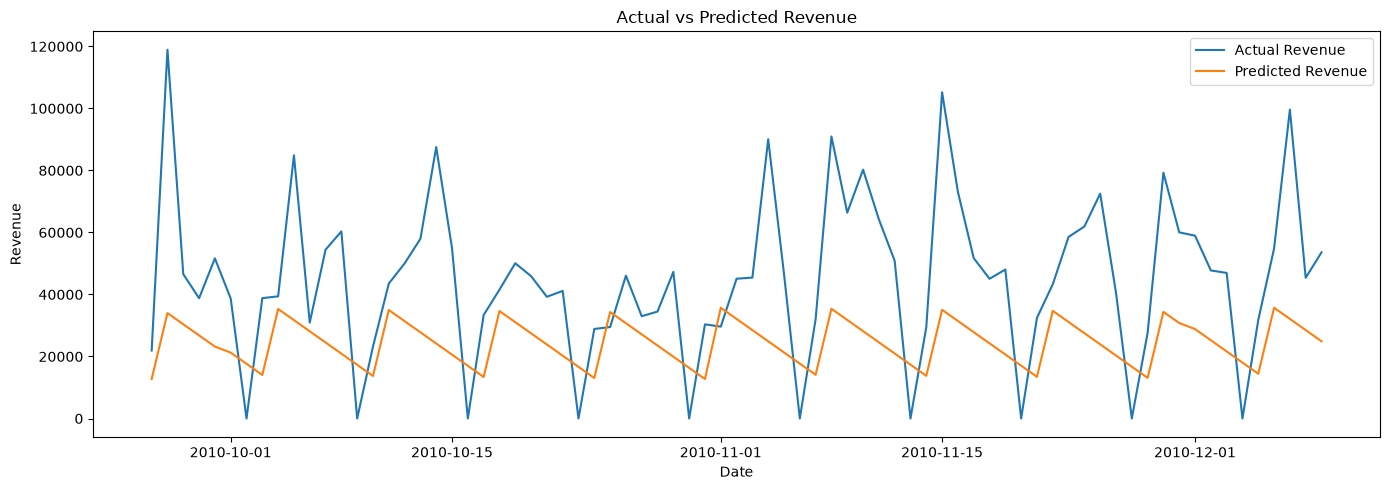

In [21]:
plt.figure(figsize=(14, 5))

plt.plot(test["Date"], test["Revenue"], label="Actual Revenue")
plt.plot(test["Date"], test["PredictedRevenue"], label="Predicted Revenue")

plt.title("Actual vs Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [23]:
rf_predictions = rf_model.predict(X_test)

test["RF_PredictedRevenue"] = rf_predictions

test[["Date", "Revenue", "RF_PredictedRevenue"]].head(10)

,Date,Revenue,RF_PredictedRevenue
299,2010-09-26,21905.72,17685.6784
300,2010-09-27,118909.67,26652.7776
301,2010-09-28,46550.84,27379.2546
302,2010-09-29,38789.98,26196.8881
303,2010-09-30,51641.94,23038.2585
304,2010-10-01,38701.58,20188.5121
305,2010-10-02,0.00,98.0305
306,2010-10-03,38809.35,10329.8747
307,2010-10-04,39399.48,28369.3636
308,2010-10-05,84879.59,28341.9459


In [24]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 19053.25464066666
Random Forest RMSE: 26711.308798533846


In [25]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ]
})

model_comparison

,Model,MAE,RMSE
0,Linear Regression,25159.336588,30166.806108
1,Random Forest,19053.254641,26711.308799


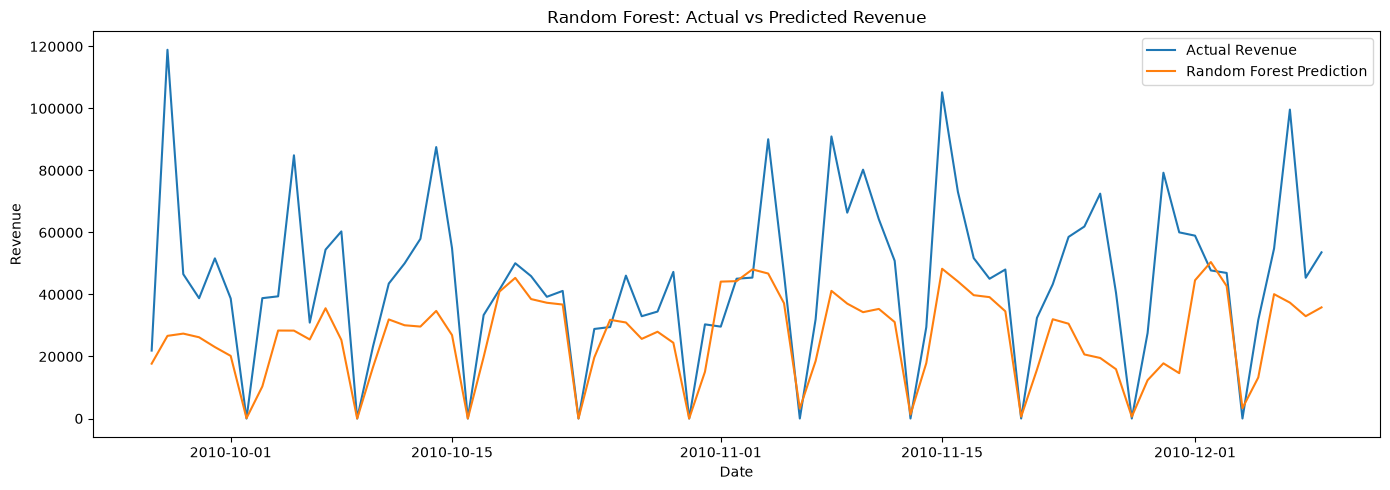

In [26]:
plt.figure(figsize=(14, 5))

plt.plot(
    test["Date"],
    test["Revenue"],
    label="Actual Revenue"
)

plt.plot(
    test["Date"],
    test["RF_PredictedRevenue"],
    label="Random Forest Prediction"
)

plt.title("Random Forest: Actual vs Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

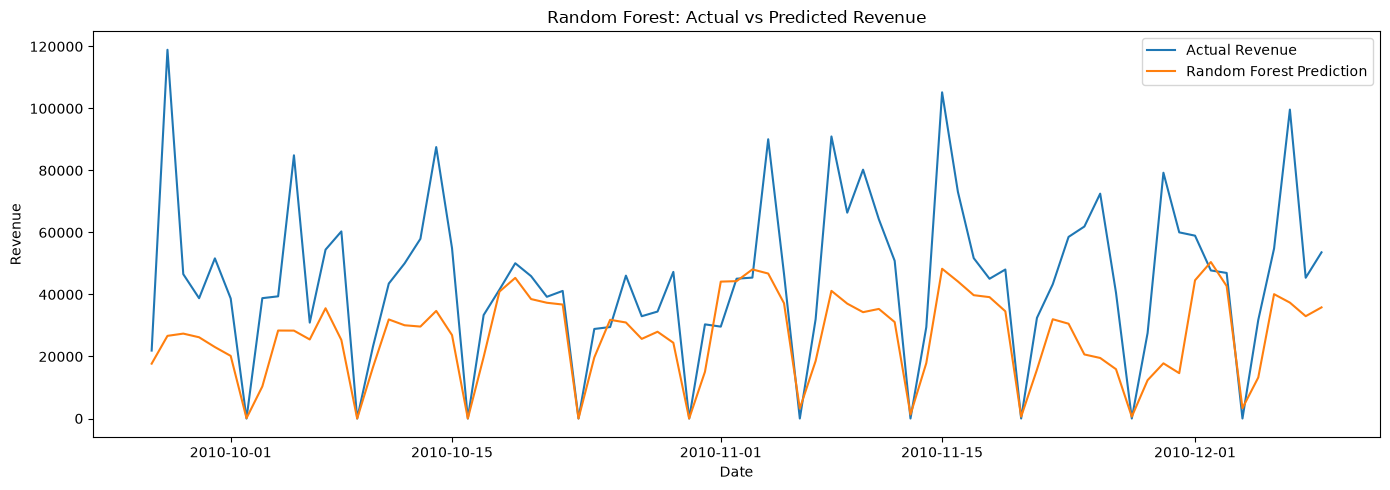

In [27]:
plt.figure(figsize=(14, 5))

plt.plot(
    test["Date"],
    test["Revenue"],
    label="Actual Revenue"
)

plt.plot(
    test["Date"],
    test["RF_PredictedRevenue"],
    label="Random Forest Prediction"
)

plt.title("Random Forest: Actual vs Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

In [28]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [29]:
xgb_model = xgb.XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [31]:
xgb_predictions = xgb_model.predict(X_test)

test["XGB_PredictedRevenue"] = xgb_predictions

test[["Date", "Revenue", "XGB_PredictedRevenue"]].head(10)

,Date,Revenue,XGB_PredictedRevenue
299,2010-09-26,21905.72,10878.133789
300,2010-09-27,118909.67,24764.248047
301,2010-09-28,46550.84,25252.271484
302,2010-09-29,38789.98,19640.666016
303,2010-09-30,51641.94,13096.929688
304,2010-10-01,38701.58,18856.820312
305,2010-10-02,0.00,3932.323242
306,2010-10-03,38809.35,17292.259766
307,2010-10-04,39399.48,30340.806641
308,2010-10-05,84879.59,27475.492188


In [32]:
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)

XGBoost MAE: 20781.776304618732
XGBoost RMSE: 28408.079668918577


In [33]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        mae,
        rf_mae,
        xgb_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse,
        xgb_rmse
    ]
})

model_comparison

,Model,MAE,RMSE
0,Linear Regression,25159.336588,30166.806108
1,Random Forest,19053.254641,26711.308799
2,XGBoost,20781.776305,28408.079669


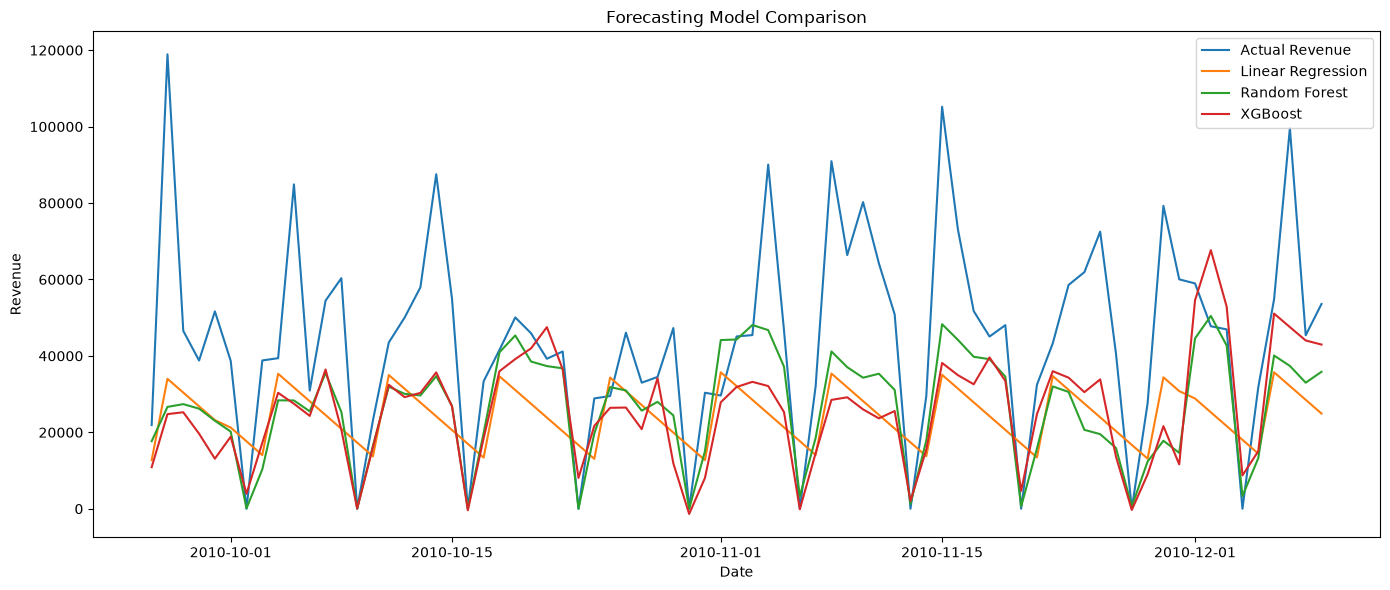

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    test["Date"],
    test["Revenue"],
    label="Actual Revenue"
)

plt.plot(
    test["Date"],
    test["PredictedRevenue"],
    label="Linear Regression"
)

plt.plot(
    test["Date"],
    test["RF_PredictedRevenue"],
    label="Random Forest"
)

plt.plot(
    test["Date"],
    test["XGB_PredictedRevenue"],
    label="XGBoost"
)

plt.title("Forecasting Model Comparison")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

In [35]:
model_comparison

,Model,MAE,RMSE
0,Linear Regression,25159.336588,30166.806108
1,Random Forest,19053.254641,26711.308799
2,XGBoost,20781.776305,28408.079669


In [36]:
print("Model Comparison")
print(model_comparison.sort_values("RMSE"))

Model Comparison
               Model           MAE          RMSE
1      Random Forest  19053.254641  26711.308799
2            XGBoost  20781.776305  28408.079669
0  Linear Regression  25159.336588  30166.806108


In [37]:
future_dates = pd.date_range(
    start=forecast_df["Date"].max() + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

future_df = pd.DataFrame({
    "Date": future_dates
})

future_df["Day"] = future_df["Date"].dt.day
future_df["Month"] = future_df["Date"].dt.month
future_df["Year"] = future_df["Date"].dt.year
future_df["DayOfWeek"] = future_df["Date"].dt.dayofweek

future_df.head()

,Date,Day,Month,Year,DayOfWeek
0,2010-12-10,10,12,2010,4
1,2010-12-11,11,12,2010,5
2,2010-12-12,12,12,2010,6
3,2010-12-13,13,12,2010,0
4,2010-12-14,14,12,2010,1


In [38]:
future_predictions = rf_model.predict(
    future_df[features]
)

future_df["PredictedRevenue"] = future_predictions

future_df.head(10)

,Date,Day,Month,Year,DayOfWeek,PredictedRevenue
0,2010-12-10,10,12,2010,4,30571.25501
1,2010-12-11,11,12,2010,5,1862.57950
2,2010-12-12,12,12,2010,6,16359.57790
3,2010-12-13,13,12,2010,0,49811.46810
4,2010-12-14,14,12,2010,1,42686.48701
5,2010-12-15,15,12,2010,2,42784.83835
6,2010-12-16,16,12,2010,3,43744.16588
7,2010-12-17,17,12,2010,4,31792.31834
8,2010-12-18,18,12,2010,5,588.18300
9,2010-12-19,19,12,2010,6,18908.85110


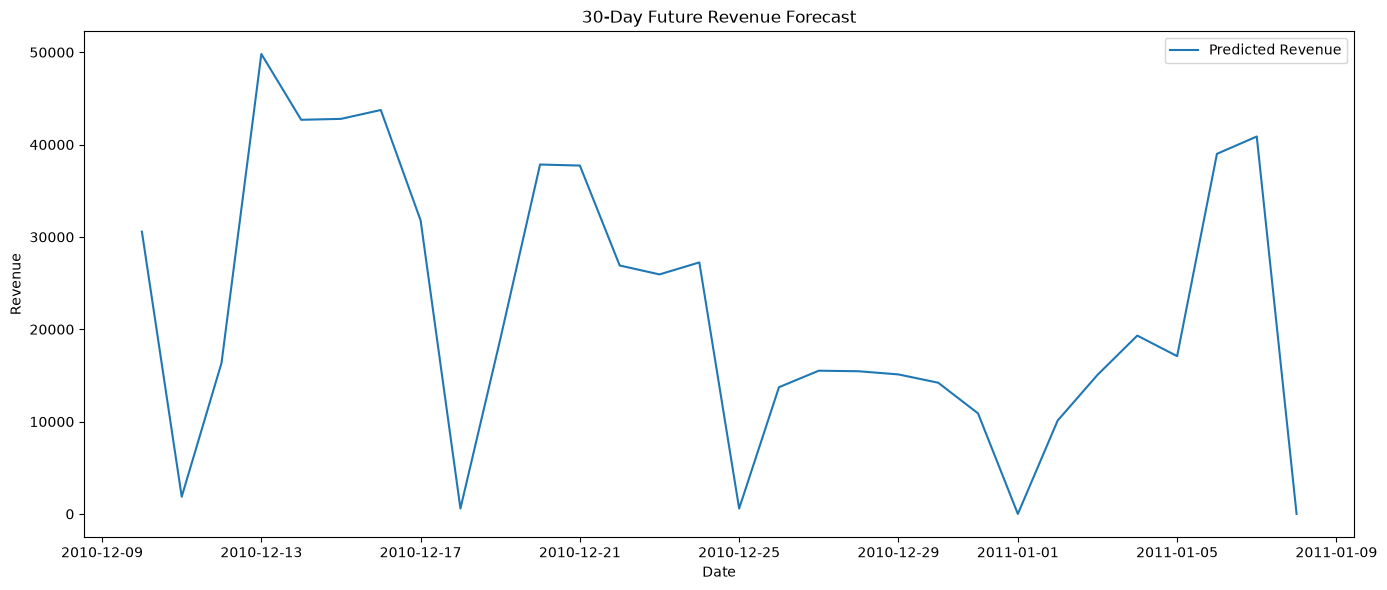

In [39]:
plt.figure(figsize=(14, 6))

plt.plot(
    future_df["Date"],
    future_df["PredictedRevenue"],
    label="Predicted Revenue"
)

plt.title("30-Day Future Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

In [40]:
future_forecast_path = "../data/future_revenue_forecast.csv"

future_df.to_csv(
    future_forecast_path,
    index=False
)

print("Future forecast saved successfully!")
print(future_forecast_path)

Future forecast saved successfully!
../data/future_revenue_forecast.csv


In [41]:
import joblib

In [42]:
model_path = "../data/random_forest_sales_model.pkl"

joblib.dump(
    rf_model,
    model_path
)

print("Random Forest model saved successfully!")
print(model_path)

Random Forest model saved successfully!
../data/random_forest_sales_model.pkl


In [43]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [44]:
print("===== SALES FORECASTING SUMMARY =====")

print("\nModel Performance:")
print(model_comparison.sort_values("RMSE"))

print("\nFuture Forecast:")
print(future_df[["Date", "PredictedRevenue"]].head())

print("\nForecast period:")
print(future_df["Date"].min(), "to", future_df["Date"].max())

===== SALES FORECASTING SUMMARY =====

Model Performance:
               Model           MAE          RMSE
1      Random Forest  19053.254641  26711.308799
2            XGBoost  20781.776305  28408.079669
0  Linear Regression  25159.336588  30166.806108

Future Forecast:
        Date  PredictedRevenue
0 2010-12-10       30571.25501
1 2010-12-11        1862.57950
2 2010-12-12       16359.57790
3 2010-12-13       49811.46810
4 2010-12-14       42686.48701

Forecast period:
2010-12-10 00:00:00 to 2011-01-08 00:00:00
